# DATA 266 — Assignment: GANs (Theory) and Autoencoders on FashionMNIST

**Student:** Ritika Mukesh Neema  |  **Runtime:** Google Colab, T4 GPU

**Step 0:** all parameters below are derived from the last four digits of my SID (6638). Per the instructions, the second hyperparameter-configuration model is skipped, since this assignment already trains two different models (FC-AE and VAE).

In [ ]:
# ===== Step 0: SID-derived parameters =====
import os, time, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SID4, SEED, SLICE, HP_ID, CLS_A, CLS_B = 6638, 6638, 638, 2, 8, 5

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figs", exist_ok=True)

RUN_LOG = []
def log(msg):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line); RUN_LOG.append(line)

log(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
log(f"torch={torch.__version__} device={device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))

[06:19:05] SID4=6638 SEED=6638 SLICE=638 HP_ID=2 CLS_A=8 CLS_B=5
[06:19:05] torch=2.11.0+cu130 device=cuda (Tesla T4)


---
# Part 1 — GAN Concepts

## 1.1 How a GAN works

A GAN is built from two neural networks that play a game against each other.

- **The generator** is like a forger. It starts from random noise and tries to turn it into something that looks like a real image. It never sees real images directly. The only feedback it gets is how well it fooled the other network.
- **The discriminator** is like a detective. It looks at an image and says how likely it is to be real (from the dataset) or fake (made by the generator).

**How they train together.** They take turns:
1. The discriminator is shown a batch of real images (the right answer is "real") and a batch of generated images (the right answer is "fake"), and it learns to tell them apart.
2. Then the generator makes new fakes and is updated so the discriminator is more likely to call them "real."

Each side improves because the other does. When the detective gets better at spotting fakes, the forger has to make better fakes. When the forger gets better, the detective has to look more carefully. The discriminator is basically a loss function that keeps getting smarter. In practice, the generator is trained to *maximize* the chance that the discriminator says "real," since this gives much stronger learning signals at the start, when the fakes are still obviously bad.

In math, this is a two-player minimax game: the discriminator tries to maximize its accuracy, and the generator tries to minimize it.

**What the game is aiming for.** In theory, the generator ends up producing images with exactly the same distribution as the real data. At that point the discriminator cannot tell real from fake and is right only about 50% of the time. Put simply, the forger has become so good that the detective is just guessing. This is the ideal case; with real networks and real data, training is often unstable and doesn't reach it perfectly, which is why the techniques below exist.

## 1.2 Mode collapse

**What it is.** Mode collapse is when the generator finds a few outputs that fool the discriminator and just keeps producing those, instead of the full variety of the real data. The images can look good, but they are all very similar. For FashionMNIST, it would be a generator that only draws sneakers and never makes shirts, bags or dresses.

**Why it happens.**
- The generator is rewarded for fooling the discriminator *right now*, not for covering every kind of image. If one type of image works well, the easiest move is to make only that.
- The two networks are updated in turns, so the generator is always reacting to the discriminator's current weaknesses. The discriminator then catches on, the generator jumps to a different single kind of image, and the cycle repeats rather than ever covering everything.
- The discriminator judges each image on its own, so nothing punishes the generator for making the same good image over and over.
- If the discriminator gets too strong too early, the generator gets almost no useful feedback, so it has no signal to push it toward the types of images it is missing.

**Two ways to reduce it.**

1. **Minibatch discrimination.** Instead of looking at each image alone, the discriminator also gets information about how similar the images in a batch are to each other. If the generator produces a batch of near-identical images, the discriminator can notice that and flag the whole batch as fake. This removes the generator's shortcut of repeating one good image and pushes it to produce a varied batch.

2. **Wasserstein GAN (WGAN-GP).** The standard GAN loss gives almost no useful feedback when the fake and real distributions don't overlap. WGAN replaces it with a distance measure (the Wasserstein or "earth mover's" distance) that gives a smooth, meaningful signal even when the generator is far off. The discriminator (now called a *critic*) is kept well-behaved with a gradient penalty. Because the critic always provides useful feedback, the generator keeps being pushed toward the parts of the data it has missed instead of settling on one. As a bonus, the critic's score tracks how good the images are, so training is much easier to monitor.

(Another well-known fix is *Unrolled GANs*, where the generator looks a few steps ahead at how the discriminator will react before it updates, so it can't exploit a temporary weakness.)

## 1.3 Three important GAN variants

### DCGAN (Deep Convolutional GAN)
- **Problem it solves:** the original GAN used plain fully-connected layers. It was hard to train and didn't work well on images.
- **What's new:** DCGAN built both networks from convolutional layers, using a set of design rules that made training stable. The discriminator uses strided convolutions to shrink the image, and the generator uses transposed convolutions to grow it, so both learn how to resize instead of using fixed pooling. It also uses batch normalization in both networks, drops fully-connected hidden layers, uses ReLU in the generator and LeakyReLU in the discriminator. It also showed that the random input space has real meaning, so doing arithmetic on the noise vectors changes image features in sensible ways.

### Conditional GAN (cGAN)
- **Problem it solves:** a basic GAN gives you no control. You get a random image and can't ask for "a dress" or "a sneaker."
- **What's new:** both networks are also given extra information, such as a class label, alongside their normal input. The generator makes an image *for that label*, and the discriminator checks both that the image looks real *and* that it matches the label. This lets you generate a specific class on demand, and it is the basis for later models like pix2pix and text-to-image GANs. It also helps against mode collapse, because the generator has to cover every class.

### CycleGAN
- **Problem it solves:** turning one kind of image into another (horses into zebras, photos into paintings) usually needs *paired* examples of the same scene in both styles, which are often impossible to get.
- **What's new:** CycleGAN works with two unpaired collections of images. It trains two generators, one for each direction (A→B and B→A), plus a discriminator for each style. The key idea is the **cycle-consistency loss**: if you translate an image to the other style and then back again, you should get the original image back. This stops the generator from producing any random realistic image in the target style, because it has to keep the content of the input so that the round trip works.

---
# Part 2 — Fully Connected AutoEncoder (FC-AE) vs. Variational AutoEncoder (VAE) on FashionMNIST

**Setup (identical for both models so the comparison is fair):** 60k train / 10k test images, pixel values in [0, 1], latent dimension 32, hidden layers 512 → 256, Adam (lr 1e-3), batch size 128, 20 epochs, seed 6638.

In [2]:
# ===== Data =====
BATCH, EPOCHS, LR, LATENT = 128, 20, 1e-3, 32
tfm = transforms.ToTensor()   # pixels scaled to [0, 1]
train_ds = datasets.FashionMNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, generator=g, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=1000, shuffle=False, num_workers=2)

CLASSES = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
log(f"train={len(train_ds)} test={len(test_ds)} | BATCH={BATCH} EPOCHS={EPOCHS} LR={LR} LATENT={LATENT}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.16MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.6MB/s]

[06:19:14] train=60000 test=10000 | BATCH=128 EPOCHS=20 LR=0.001 LATENT=32


In [3]:
# ===== Models =====
class FCAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU(), nn.Linear(256, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(), nn.Linear(512, 784), nn.Sigmoid())
    def encode(self, x): return self.enc(x.view(x.size(0), -1))
    def decode(self, z): return self.dec(z).view(-1, 1, 28, 28)
    def forward(self, x):
        z = self.encode(x); return self.decode(z), z

class VAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        self.mu, self.logvar = nn.Linear(256, latent), nn.Linear(256, latent)
        self.dec = nn.Sequential(nn.Linear(latent, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(), nn.Linear(512, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.enc(x.view(x.size(0), -1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # z = mu + sigma * eps
    def decode(self, z): return self.dec(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def ae_loss(model, x):
    recon, _ = model(x)
    return F.mse_loss(recon, x, reduction="mean")                      # per-pixel MSE

def vae_loss(model, x):
    recon, mu, logvar = model(x)
    bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)               # reconstruction term (per image)
    kl  = (-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())) / x.size(0)       # KL(q(z|x) || N(0, I)) per image
    return bce + kl, bce, kl

n_params = lambda m: sum(p.numel() for p in m.parameters())
log(f"FC-AE params={n_params(FCAE()):,} | VAE params={n_params(VAE()):,}")

[06:19:14] FC-AE params=1,083,696 | VAE params=1,091,920


In [4]:
# ===== Evaluation helpers (shared) =====
@torch.no_grad()
def eval_recon_mse(model, kind):
    """Deterministic reconstruction MSE per pixel on the test set (VAE uses the posterior mean)."""
    model.eval(); tot, n = 0.0, 0
    for x, _ in test_loader:
        x = x.to(device)
        recon = model.decode(model.encode(x)) if kind == "ae" else model.decode(model.encode(x)[0])
        tot += F.mse_loss(recon, x, reduction="sum").item(); n += x.numel()
    return tot / n

@torch.no_grad()
def eval_loss(model, kind):
    model.eval(); tot, n = 0.0, 0
    for x, _ in test_loader:
        x = x.to(device)
        l = ae_loss(model, x) if kind == "ae" else vae_loss(model, x)[0]
        tot += l.item() * x.size(0); n += x.size(0)
    return tot / n

def train_model(model, kind, name):
    model.to(device); opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train_loss": [], "test_loss": [], "test_mse": [], "train_bce": [], "train_kl": []}
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot, n, tb, tk = 0.0, 0, 0.0, 0.0
        for x, _ in train_loader:
            x = x.to(device); opt.zero_grad()
            if kind == "ae":
                loss = ae_loss(model, x)
            else:
                loss, bce, kl = vae_loss(model, x); tb += bce.item() * x.size(0); tk += kl.item() * x.size(0)
            loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        hist["train_loss"].append(tot / n); hist["test_loss"].append(eval_loss(model, kind)); hist["test_mse"].append(eval_recon_mse(model, kind))
        if kind == "vae": hist["train_bce"].append(tb / n); hist["train_kl"].append(tk / n)
        log(f"{name} epoch {ep:02d}/{EPOCHS} train_loss={hist['train_loss'][-1]:.5f} test_loss={hist['test_loss'][-1]:.5f} test_MSE={hist['test_mse'][-1]:.5f}")
    hist["time_s"] = time.time() - t0
    log(f"{name} finished in {hist['time_s']:.1f}s")
    return hist

## 2.1 Train the FC-AE

In [5]:
torch.manual_seed(SEED)
fcae = FCAE(); h_ae = train_model(fcae, "ae", "FC-AE")

[06:19:24] FC-AE epoch 01/20 train_loss=0.03313 test_loss=0.02027 test_MSE=0.02027
[06:19:33] FC-AE epoch 02/20 train_loss=0.01797 test_loss=0.01619 test_MSE=0.01619
[06:19:42] FC-AE epoch 03/20 train_loss=0.01527 test_loss=0.01461 test_MSE=0.01461
[06:19:51] FC-AE epoch 04/20 train_loss=0.01366 test_loss=0.01320 test_MSE=0.01320
[06:20:00] FC-AE epoch 05/20 train_loss=0.01257 test_loss=0.01228 test_MSE=0.01228
[06:20:10] FC-AE epoch 06/20 train_loss=0.01186 test_loss=0.01166 test_MSE=0.01166
[06:20:19] FC-AE epoch 07/20 train_loss=0.01132 test_loss=0.01123 test_MSE=0.01123
[06:20:29] FC-AE epoch 08/20 train_loss=0.01087 test_loss=0.01110 test_MSE=0.01110
[06:20:40] FC-AE epoch 09/20 train_loss=0.01046 test_loss=0.01052 test_MSE=0.01052
[06:20:49] FC-AE epoch 10/20 train_loss=0.01011 test_loss=0.01015 test_MSE=0.01015
[06:20:58] FC-AE epoch 11/20 train_loss=0.00977 test_loss=0.00988 test_MSE=0.00988
[06:21:07] FC-AE epoch 12/20 train_loss=0.00952 test_loss=0.00963 test_MSE=0.00963
[06:

## 2.2 Train the VAE

In [6]:
torch.manual_seed(SEED)
vae = VAE(); h_vae = train_model(vae, "vae", "VAE")

[06:22:34] VAE epoch 01/20 train_loss=290.88404 test_loss=261.90920 test_MSE=0.02768
[06:22:45] VAE epoch 02/20 train_loss=254.62261 test_loss=252.22392 test_MSE=0.02213
[06:22:54] VAE epoch 03/20 train_loss=248.92680 test_loss=249.13588 test_MSE=0.02012
[06:23:04] VAE epoch 04/20 train_loss=246.62870 test_loss=247.48078 test_MSE=0.01922
[06:23:14] VAE epoch 05/20 train_loss=245.06698 test_loss=246.37442 test_MSE=0.01835
[06:23:24] VAE epoch 06/20 train_loss=243.91640 test_loss=245.50551 test_MSE=0.01778
[06:23:33] VAE epoch 07/20 train_loss=242.99737 test_loss=244.25161 test_MSE=0.01706
[06:23:43] VAE epoch 08/20 train_loss=242.14910 test_loss=243.61723 test_MSE=0.01669
[06:23:53] VAE epoch 09/20 train_loss=241.40911 test_loss=242.96309 test_MSE=0.01636
[06:24:03] VAE epoch 10/20 train_loss=240.71826 test_loss=242.16510 test_MSE=0.01602
[06:24:13] VAE epoch 11/20 train_loss=240.26170 test_loss=242.02458 test_MSE=0.01590
[06:24:23] VAE epoch 12/20 train_loss=239.96198 test_loss=241.942

## 2.3 Quantitative evaluation and training curves

[06:25:44] TEST recon MSE/pixel  FC-AE=0.00843 (PSNR 20.74 dB) | VAE=0.01510 (PSNR 18.21 dB)
[06:25:44] VAE test: BCE/img=228.39  KL/img=11.93  negative ELBO/img=240.32


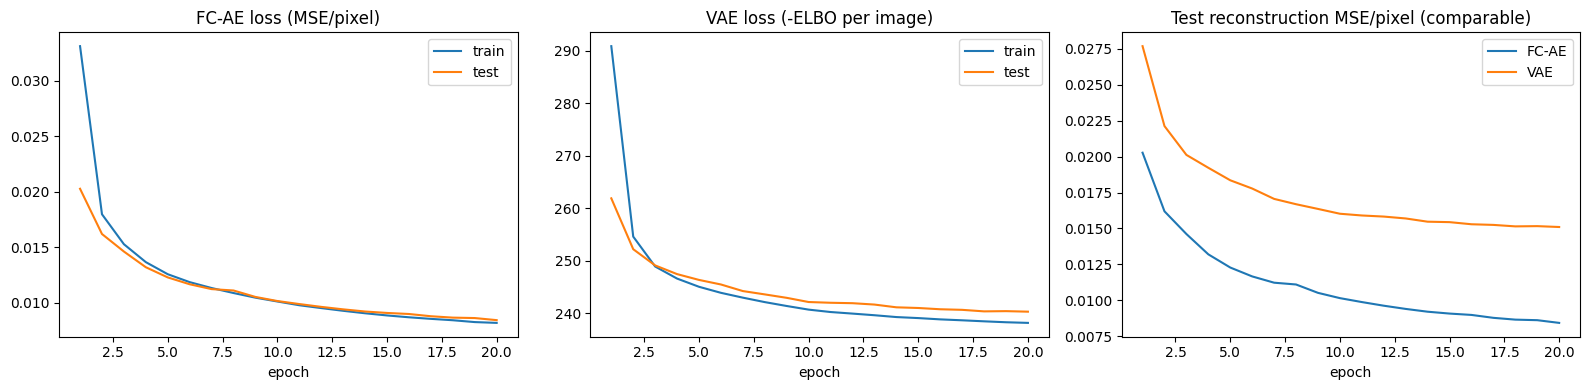

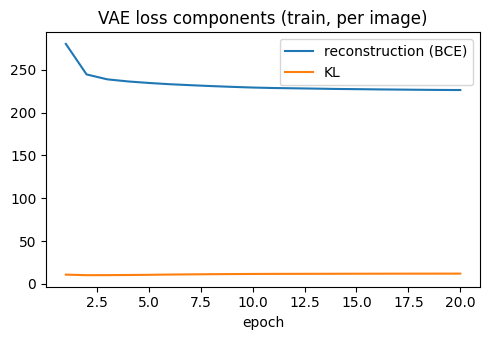

In [7]:
mse_ae, mse_vae = eval_recon_mse(fcae, "ae"), eval_recon_mse(vae, "vae")
psnr = lambda mse: 10 * np.log10(1.0 / mse)

# VAE test ELBO terms per image
@torch.no_grad()
def vae_test_terms():
    vae.eval(); tb = tk = 0.0; n = 0
    for x, _ in test_loader:
        x = x.to(device); _, bce, kl = vae_loss(vae, x); tb += bce.item() * x.size(0); tk += kl.item() * x.size(0); n += x.size(0)
    return tb / n, tk / n
bce_t, kl_t = vae_test_terms()

log(f"TEST recon MSE/pixel  FC-AE={mse_ae:.5f} (PSNR {psnr(mse_ae):.2f} dB) | VAE={mse_vae:.5f} (PSNR {psnr(mse_vae):.2f} dB)")
log(f"VAE test: BCE/img={bce_t:.2f}  KL/img={kl_t:.2f}  negative ELBO/img={bce_t + kl_t:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ep = range(1, EPOCHS + 1)
ax[0].plot(ep, h_ae["train_loss"], label="train"); ax[0].plot(ep, h_ae["test_loss"], label="test")
ax[0].set_title("FC-AE loss (MSE/pixel)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, h_vae["train_loss"], label="train"); ax[1].plot(ep, h_vae["test_loss"], label="test")
ax[1].set_title("VAE loss (-ELBO per image)"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].plot(ep, h_ae["test_mse"], label="FC-AE"); ax[2].plot(ep, h_vae["test_mse"], label="VAE")
ax[2].set_title("Test reconstruction MSE/pixel (comparable)"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.savefig("figs/loss_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(ep, h_vae["train_bce"], label="reconstruction (BCE)"); ax.plot(ep, h_vae["train_kl"], label="KL")
ax.set_title("VAE loss components (train, per image)"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig("figs/vae_loss_components.png", dpi=150); plt.show()

## 2.4 Reconstructions (same test images for both models)

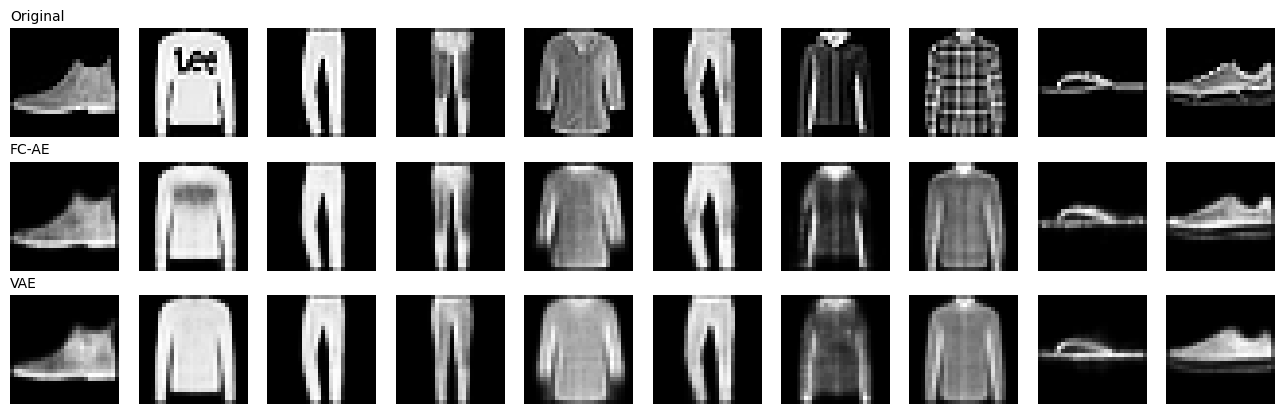

In [8]:
@torch.no_grad()
def show_recon(n=10):
    fcae.eval(); vae.eval()
    x, y = next(iter(test_loader)); x = x[:n].to(device)
    r_ae = fcae.decode(fcae.encode(x)); r_vae = vae.decode(vae.encode(x)[0])
    rows = [("Original", x), ("FC-AE", r_ae), ("VAE", r_vae)]
    fig, axes = plt.subplots(3, n, figsize=(1.3 * n, 4.2))
    for r, (title, imgs) in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(imgs[c, 0].cpu(), cmap="gray"); axes[r, c].axis("off")
        axes[r, 0].set_title(title, loc="left", fontsize=10)
    plt.tight_layout(); plt.savefig("figs/reconstructions.png", dpi=150); plt.show()
show_recon()

## 2.5 Generation from the prior: sampling $z \sim \mathcal{N}(0, I)$ and decoding

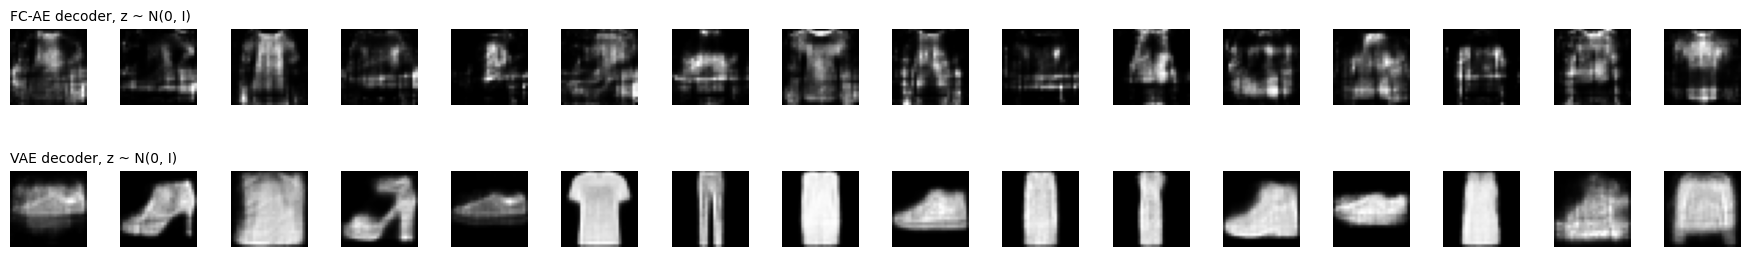

In [9]:
@torch.no_grad()
def show_samples(n=16):
    torch.manual_seed(SEED)
    z = torch.randn(n, LATENT, device=device)
    fcae.eval(); vae.eval()
    outs = [("FC-AE decoder, z ~ N(0, I)", fcae.decode(z)), ("VAE decoder, z ~ N(0, I)", vae.decode(z))]
    fig, axes = plt.subplots(2, n, figsize=(1.1 * n, 3.2))
    for r, (title, imgs) in enumerate(outs):
        for c in range(n):
            axes[r, c].imshow(imgs[c, 0].cpu(), cmap="gray"); axes[r, c].axis("off")
        axes[r, 0].set_title(title, loc="left", fontsize=10)
    plt.tight_layout(); plt.savefig("figs/samples_from_prior.png", dpi=150); plt.show()
show_samples()

## 2.6 Latent-space quality: 2-D t-SNE and linear-probe accuracy

[06:26:17] Linear probe on frozen 32-d latents (test acc): FC-AE=0.8267 | VAE (posterior mean)=0.8068


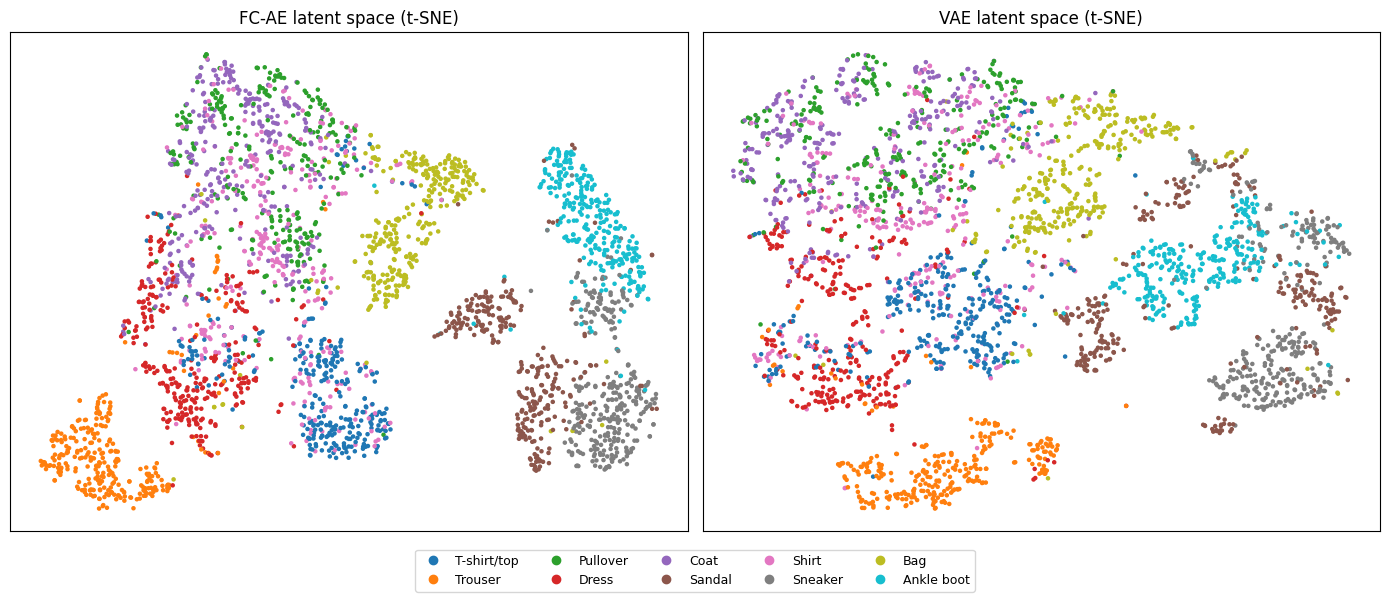

In [10]:
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

@torch.no_grad()
def get_latents(model, kind, loader):
    model.eval(); Z, Y = [], []
    for x, y in loader:
        x = x.to(device); z = model.encode(x) if kind == "ae" else model.encode(x)[0]
        Z.append(z.cpu()); Y.append(y)
    return torch.cat(Z).numpy(), torch.cat(Y).numpy()

train_eval_loader = DataLoader(train_ds, batch_size=1000, shuffle=False, num_workers=2)
Z_ae_tr, y_tr = get_latents(fcae, "ae", train_eval_loader);  Z_ae_te, y_te = get_latents(fcae, "ae", test_loader)
Z_vae_tr, _   = get_latents(vae, "vae", train_eval_loader);  Z_vae_te, _   = get_latents(vae, "vae", test_loader)

def probe(Ztr, Zte):
    sc = StandardScaler().fit(Ztr)
    clf = LogisticRegression(max_iter=1000).fit(sc.transform(Ztr), y_tr)
    return clf.score(sc.transform(Zte), y_te)
acc_ae, acc_vae = probe(Z_ae_tr, Z_ae_te), probe(Z_vae_tr, Z_vae_te)
log(f"Linear probe on frozen 32-d latents (test acc): FC-AE={acc_ae:.4f} | VAE (posterior mean)={acc_vae:.4f}")

rng = np.random.RandomState(SEED); idx = rng.choice(len(y_te), min(3000, len(y_te)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (Z, title) in zip(ax, [(Z_ae_te, "FC-AE latent space (t-SNE)"), (Z_vae_te, "VAE latent space (t-SNE)")]):
    E = TSNE(n_components=2, random_state=SEED, init="pca", perplexity=30).fit_transform(Z[idx])
    sc_ = a.scatter(E[:, 0], E[:, 1], c=y_te[idx], cmap="tab10", s=5); a.set_title(title); a.set_xticks([]); a.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i / 9), label=CLASSES[i]) for i in range(10)]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.savefig("figs/latent_tsne.png", dpi=150); plt.show()

## 2.7 Latent interpolation between two test images

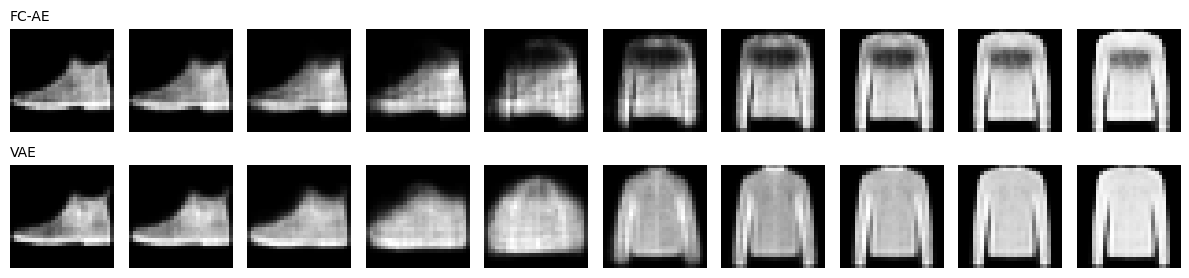

In [11]:
@torch.no_grad()
def show_interp(steps=10):
    fcae.eval(); vae.eval()
    x, y = next(iter(test_loader)); a, b = x[0:1].to(device), x[1:2].to(device)
    alphas = torch.linspace(0, 1, steps, device=device).view(-1, 1)
    za, zb = fcae.encode(a), fcae.encode(b); ia = fcae.decode((1 - alphas) * za + alphas * zb)
    ma, mb = vae.encode(a)[0], vae.encode(b)[0]; iv = vae.decode((1 - alphas) * ma + alphas * mb)
    fig, axes = plt.subplots(2, steps, figsize=(1.2 * steps, 3))
    for r, (t, imgs) in enumerate([("FC-AE", ia), ("VAE", iv)]):
        for c in range(steps):
            axes[r, c].imshow(imgs[c, 0].cpu(), cmap="gray"); axes[r, c].axis("off")
        axes[r, 0].set_title(t, loc="left", fontsize=10)
    plt.tight_layout(); plt.savefig("figs/interpolation.png", dpi=150); plt.show()
show_interp()

## 2.8 Export metrics and run log

In [12]:
metrics = f"""# METRICS — FC-AE vs VAE on FashionMNIST

SID4={SID4} | SEED={SEED} | SLICE={SLICE} | HP_ID={HP_ID} | CLS_A={CLS_A} | CLS_B={CLS_B}
Config: latent={LATENT}, hidden=512-256, Adam lr={LR}, batch={BATCH}, epochs={EPOCHS}

| Metric | FC-AE | VAE |
|---|---|---|
| Parameters | {n_params(fcae):,} | {n_params(vae):,} |
| Final train loss | {h_ae['train_loss'][-1]:.5f} (MSE/px) | {h_vae['train_loss'][-1]:.2f} (-ELBO/img) |
| Final test loss | {h_ae['test_loss'][-1]:.5f} (MSE/px) | {h_vae['test_loss'][-1]:.2f} (-ELBO/img) |
| Test recon MSE/pixel | {mse_ae:.5f} | {mse_vae:.5f} |
| Test PSNR (dB) | {psnr(mse_ae):.2f} | {psnr(mse_vae):.2f} |
| VAE test BCE / KL per image | - | {bce_t:.2f} / {kl_t:.2f} |
| Linear-probe test accuracy (32-d latent) | {acc_ae:.4f} | {acc_vae:.4f} |
| Training time (s) | {h_ae['time_s']:.1f} | {h_vae['time_s']:.1f} |
"""
open("METRICS.md", "w").write(metrics); print(metrics)
open("RUN_LOG.txt", "w").write("\n".join(RUN_LOG)); log("Wrote METRICS.md and RUN_LOG.txt")

# METRICS — FC-AE vs VAE on FashionMNIST

SID4=6638 | SEED=6638 | SLICE=638 | HP_ID=2 | CLS_A=8 | CLS_B=5
Config: latent=32, hidden=512-256, Adam lr=0.001, batch=128, epochs=20

| Metric | FC-AE | VAE |
|---|---|---|
| Parameters | 1,083,696 | 1,091,920 |
| Final train loss | 0.00818 (MSE/px) | 238.19 (-ELBO/img) |
| Final test loss | 0.00843 (MSE/px) | 240.33 (-ELBO/img) |
| Test recon MSE/pixel | 0.00843 | 0.01510 |
| Test PSNR (dB) | 20.74 | 18.21 |
| VAE test BCE / KL per image | - | 228.39 / 11.93 |
| Linear-probe test accuracy (32-d latent) | 0.8267 | 0.8068 |
| Training time (s) | 190.5 | 196.5 |

[06:27:05] Wrote METRICS.md and RUN_LOG.txt


## 2.9 Analysis

*Numbers below are from the Colab T4 run recorded in this notebook (seed 6638, 20 epochs, latent size 32).*

**Reconstruction quality: the FC-AE wins.** The FC-AE reaches a test reconstruction MSE of 0.00843 per pixel (20.74 dB PSNR) versus 0.01510 (18.21 dB) for the VAE, so its error is roughly 44% lower. In the reconstruction grid the FC-AE keeps finer detail (the plaid pattern on the shirt, the stripes on the jacket, the sole of the sneaker), while the VAE outputs are smoother and lose texture. It is a trade-off, not a flaw: the FC-AE optimizes only reconstruction error, while the VAE minimizes reconstruction plus a KL term (about 12 nats per image on the test set, against about 228 for reconstruction). The KL term makes the encoder emit noisy, overlapping posteriors, so the decoder cannot rely on exact latent coordinates and learns to output the average of everything compatible with a code. That is the blur. The FC-AE is also still improving at epoch 20 (test MSE 0.00866 → 0.00862 → 0.00843 over the last three epochs), so a longer run would widen the gap slightly; the VAE curve is flatter.

**Generation from the prior: only the VAE works.** Decoding $z \sim \mathcal{N}(0, I)$ gives recognizable garments from the VAE (sneakers, ankle boots, a high-heeled shoe, a T-shirt, trousers, dresses), although some are blurry. This is because the KL term pulls every posterior toward the standard normal, so the region the decoder is trained on matches the region we sample from. The FC-AE decoder gives noisy, fragmented, texture-like shapes from the same noise: nothing constrains its codes to any distribution, so a random Gaussian vector lands in "holes" between the codes the decoder has actually seen. The FC-AE is a good compressor but not a generative model; the VAE is both, at the price of blurrier reconstructions.

**Latent-space structure.** Both t-SNE plots separate the visually distinct classes (trousers, bags, ankle boots, and the footwear group) and both confuse the same hard group (shirt, T-shirt, pullover, coat), which is expected for a 32-d unsupervised code. The linear probe agrees: 82.7% for the FC-AE versus 80.7% for the VAE, a small gap, so the extra regularization of the VAE costs little class information even though the objective never saw labels. The two maps look broadly similar; the VAE's clusters are somewhat more diffuse and adjacent, consistent with its codes being pushed toward a common Gaussian.

**Interpolation.** In the FC-AE, the interpolation between an ankle boot and a pullover stays on the boot for several steps, then flips abruptly through a degraded, texture-heavy intermediate, which indicates a less smooth latent space with gaps. The VAE transitions more gradually, though its midpoint is a blurry blob rather than a crisp object. This is the practical payoff of the KL regularization: a smoother, more continuous latent space.

**Takeaway.** Choose the FC-AE when the goal is faithful reconstruction or compact features (compression, denoising, feature extraction). Choose the VAE when the goal is generation or a smooth, samplable latent space. Possible improvements: convolutional encoders and decoders for sharper images from both models; a larger latent size or lower KL weight ($\beta < 1$) for the VAE to trade smoothness for detail; and a perceptual or adversarial loss (e.g. VAE-GAN, which connects back to Part 1) to reduce VAE blur.